## Problema 1 - Regressão Linear Múltipla

### 1. Carregamento e exploração dos dados

In [4]:
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=294)

X = dataset.data.features
y = dataset.data.targets

df = pd.concat([X, y], axis=1)

display(df.head())

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


In [5]:
print("Dimensões:", df.shape)

print("\nInformações gerais:")
df.info()

print("\nValores ausentes:")
print(df.isnull().sum())

print("\nEstatísticas descritivas:")
display(df.describe())

Dimensões: (9568, 5)

Informações gerais:
<class 'pandas.DataFrame'>
RangeIndex: 9568 entries, 0 to 9567
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AT      9568 non-null   float64
 1   V       9568 non-null   float64
 2   AP      9568 non-null   float64
 3   RH      9568 non-null   float64
 4   PE      9568 non-null   float64
dtypes: float64(5)
memory usage: 373.9 KB

Valores ausentes:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

Estatísticas descritivas:


,AT,V,AP,RH,PE
count,9568.000000,9568.000000,9568.000000,9568.000000,9568.000000
mean,19.651231,54.305804,1013.259078,73.308978,454.365009
std,7.452473,12.707893,5.938784,14.600269,17.066995
min,1.810000,25.360000,992.890000,25.560000,420.260000
25%,13.510000,41.740000,1009.100000,63.327500,439.750000
50%,20.345000,52.080000,1012.940000,74.975000,451.550000
75%,25.720000,66.540000,1017.260000,84.830000,468.430000
max,37.110000,81.560000,1033.300000,100.160000,495.760000


## 2. Análise de correlação

### 2.1. Correlação entre as variáveis independentes e PE

In [6]:
correlacao = df.corr(method="pearson")

correlacao_pe = correlacao["PE"].drop("PE")

correlacao_pe = correlacao_pe.sort_values(
    key=abs,
    ascending=False
)

display(correlacao_pe)

AT   -0.948128
V    -0.869780
AP    0.518429
RH    0.389794
Name: PE, dtype: float64

### 2.2. Correlação entre as variáveis independentes

In [7]:
variaveis = ["AT", "V", "AP", "RH"]

correlacao_independentes = df[variaveis].corr()

display(correlacao_independentes)

,AT,V,AP,RH
AT,1.000000,0.844107,-0.507549,-0.542535
V,0.844107,1.000000,-0.413502,-0.312187
AP,-0.507549,-0.413502,1.000000,0.099574
RH,-0.542535,-0.312187,0.099574,1.000000


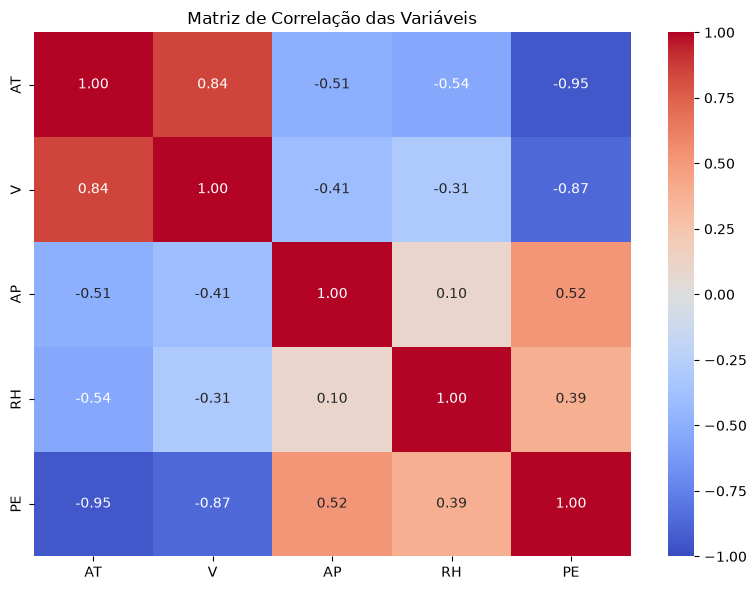

In [8]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlacao,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Matriz de Correlação das Variáveis")
plt.tight_layout()
plt.show()

## 3. Treinamento do Modelo

### 3.1. Divisão dos dados em treino e teste

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[["AT", "V", "AP", "RH"]]
y = df["PE"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Amostras de treino:", X_treino.shape)
print("Amostras de teste:", X_teste.shape)

Amostras de treino: (7654, 4)
Amostras de teste: (1914, 4)


### 3.2. Padronização dos atributos

In [10]:
scaler = StandardScaler()
 
X_treino_pad = scaler.fit_transform(X_treino)

X_teste_pad = scaler.transform(X_teste)

print("Médias:", X_treino_pad.mean(axis=0))
print("Desvios:", X_treino_pad.std(axis=0))

Médias: [-3.98252984e-16 -1.87986548e-16 -3.82239315e-15  2.29761337e-17]
Desvios: [1. 1. 1. 1.]


### 3.3. Conversão dos dados para tensores

In [11]:
X_treino_tensor = torch.tensor(
    X_treino_pad,
    dtype=torch.float32
)

y_treino_tensor = torch.tensor(
    y_treino.to_numpy().reshape(-1, 1),
    dtype=torch.float32
)

X_teste_tensor = torch.tensor(
    X_teste_pad,
    dtype=torch.float32
)

y_teste_tensor = torch.tensor(
    y_teste.to_numpy().reshape(-1, 1),
    dtype=torch.float32
)

print("Entradas de treino:", X_treino_tensor.shape)
print("Saídas de treino:", y_treino_tensor.shape)

Entradas de treino: torch.Size([7654, 4])
Saídas de treino: torch.Size([7654, 1])


### 3.4. Implementação e treinamento da regressão linear

In [12]:
import torch.nn as nn

torch.manual_seed(42)

modelo = nn.Linear(4, 1)

with torch.no_grad():
    modelo.bias.fill_(float(y_treino.mean()))

# Função de perda: erro quadrático médio
criterio = nn.MSELoss()

otimizador = torch.optim.Adam(
    modelo.parameters(),
    lr=0.05
)

epocas = 2000
historico_perda = []

for epoca in range(epocas):

    previsoes = modelo(X_treino_tensor)

    # Calculando o erro
    perda = criterio(previsoes, y_treino_tensor)

    # Zerando gradientes anteriores
    otimizador.zero_grad()

    # Calculando os gradientes
    perda.backward()

    # Atualizando os parâmetros
    otimizador.step()

    # Registrando a perda
    historico_perda.append(perda.item())

    if (epoca + 1) % 200 == 0:
        print(
            f"Época {epoca + 1}/{epocas} "
            f"- MSE: {perda.item():.4f}"
        )

Época 200/2000 - MSE: 42.3955
Época 400/2000 - MSE: 28.2200
Época 600/2000 - MSE: 25.0967
Época 800/2000 - MSE: 23.2214
Época 1000/2000 - MSE: 22.0415
Época 1200/2000 - MSE: 21.3941
Época 1400/2000 - MSE: 21.0851
Época 1600/2000 - MSE: 20.9572
Época 1800/2000 - MSE: 20.9117
Época 2000/2000 - MSE: 20.8978


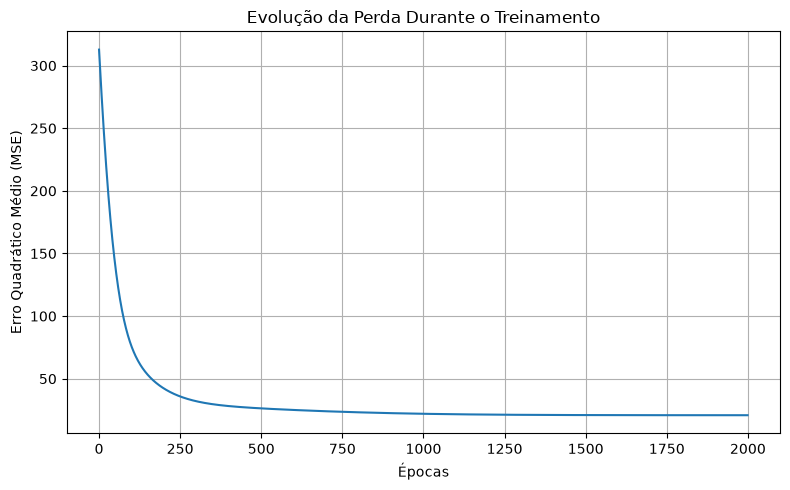

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(historico_perda)

plt.title("Evolução da Perda Durante o Treinamento")
plt.xlabel("Épocas")
plt.ylabel("Erro Quadrático Médio (MSE)")

plt.grid(True)
plt.tight_layout()
plt.show()

## 4. Avaliação do Modelo

### 4.1. Previsões nos conjuntos de treino e teste

In [15]:
modelo.eval()

with torch.no_grad():
    pred_treino = modelo(X_treino_tensor).numpy().flatten()
    pred_teste = modelo(X_teste_tensor).numpy().flatten()

real_treino = y_treino.to_numpy()
real_teste = y_teste.to_numpy()

comparacao = pd.DataFrame({
    "Valor Real (MW)": real_teste,
    "Valor Previsto (MW)": pred_teste
})

display(comparacao.head(10))

,Valor Real (MW),Valor Previsto (MW)
0,455.27,455.754120
1,436.31,438.674713
2,440.68,434.202789
3,434.40,438.704529
4,482.06,479.834900
5,436.07,439.485657
6,452.48,448.853485
7,435.22,434.777679
8,432.93,435.072205
9,466.46,472.987732


### 4.2. Cálculo das métricas de desempenho

In [16]:
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# Função para calcular as métricas
def calcular_metricas(real, previsto):
    r2 = r2_score(real, previsto)
    rmse = np.sqrt(mean_squared_error(real, previsto))
    mae = mean_absolute_error(real, previsto)

    return {
        "R²": r2,
        "RMSE (MW)": rmse,
        "MAE (MW)": mae
    }

metricas_treino = calcular_metricas(real_treino, pred_treino)
metricas_teste = calcular_metricas(real_teste, pred_teste)

resultados = pd.DataFrame({
    "Treino": metricas_treino,
    "Teste": metricas_teste
}).T

display(resultados.round(4))

,R²,RMSE (MW),MAE (MW)
Treino,0.9283,4.5714,3.6323
Teste,0.9301,4.5016,3.5954


In [17]:
previsao_media = np.full_like(
    real_teste,
    real_treino.mean()
)

# Avaliando a referência
metricas_referencia = calcular_metricas(
    real_teste,
    previsao_media
)

comparacao_modelos = pd.DataFrame({
    "Regressão Linear": metricas_teste,
    "Previsão pela Média": metricas_referencia
}).T

display(comparacao_modelos.round(4))

,R²,RMSE (MW),MAE (MW)
Regressão Linear,0.9301,4.5016,3.5954
Previsão pela Média,-0.0004,17.0343,14.8067


### 4.3. Comparação entre valores reais e previstos

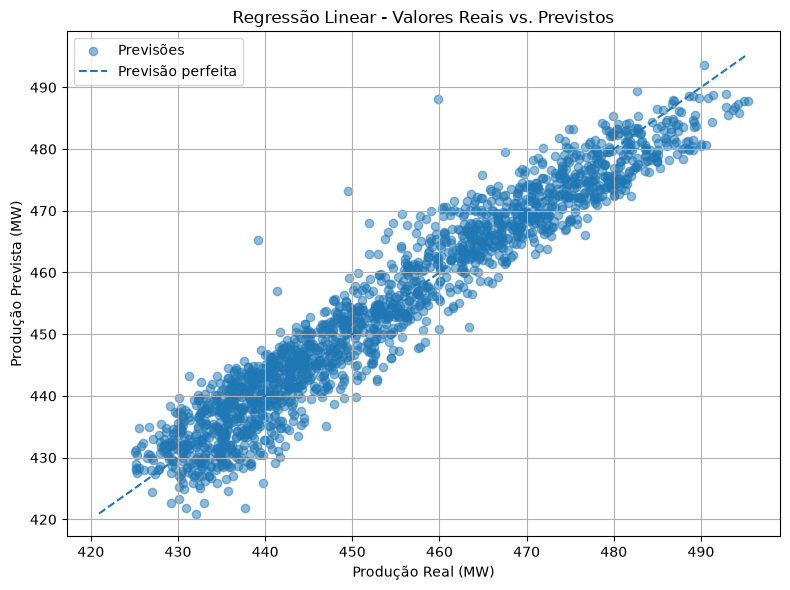

In [18]:
plt.figure(figsize=(8, 6))

# Pontos com valores reais e previstos
plt.scatter(
    real_teste,
    pred_teste,
    alpha=0.5,
    label="Previsões"
)

# Linha de previsão perfeita
limites = [
    min(real_teste.min(), pred_teste.min()),
    max(real_teste.max(), pred_teste.max())
]

plt.plot(
    limites,
    limites,
    "--",
    label="Previsão perfeita"
)

plt.xlabel("Produção Real (MW)")
plt.ylabel("Produção Prevista (MW)")
plt.title("Regressão Linear - Valores Reais vs. Previstos")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### 4.4. Análise dos resíduos

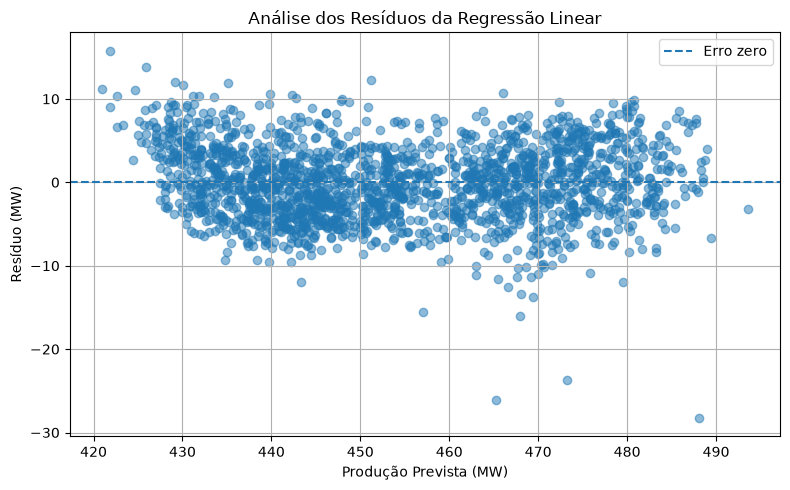

In [19]:
# Calculando os resíduos
residuos = real_teste - pred_teste

plt.figure(figsize=(8, 5))

plt.scatter(
    pred_teste,
    residuos,
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle="--",
    label="Erro zero"
)

plt.xlabel("Produção Prevista (MW)")
plt.ylabel("Resíduo (MW)")
plt.title("Análise dos Resíduos da Regressão Linear")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()